# 02 · Feature engineering y diseño experimental (Paso 06)

**Proyecto:** UrbanSafe CABA · **Skills aplicadas:** `spatiotemporal-ml`, `jupyter-notebooks` y `ml-scientific-reviewer` (al cierre)

**Propósito.** Construir variables conocidas al momento del pronóstico, fijar los objetivos y las particiones temporales compartidas por la regresión y la clasificación, y **demostrar** que no hay fuga temporal. El protocolo completo está en [docs/experimental_protocol.md](../docs/experimental_protocol.md).

| Elemento | Definición |
|---|---|
| Unidad | Barrio (48) × mes |
| Horizonte | h = 1: con información hasta el mes T−1 se pronostica el mes T |
| Último mes observable | L = T − h − gap. Configuración principal: gap = 0. Sensibilidad a la latencia de publicación: gap = 1 |
| Objetivos | `y_target`: hechos del mes T (regresión). `top10_target`: el barrio está en el top 10 de T, con desempate R0 (clasificación) |
| Código | [`src/features.py`](../src/features.py) y [`src/labels.py`](../src/labels.py). Pruebas en [`tests/test_features.py`](../tests/test_features.py) |
| Salidas | `data/processed/features_barrio_mes_h1_g{0,1}.csv`, `reports/tables/02_feature_engineering/` y `reports/figures/02_feature_engineering/` |

**Regla.** El test de 2025 se **congela**: ninguna celda de este notebook calcula estadísticas con meses objetivo de 2025, salvo para contar filas.

In [1]:
import json, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
import sys; sys.path.insert(0, str(ROOT))
from src import features as F
FIG, TAB = ROOT / "reports" / "figures" / "02_feature_engineering", ROOT / "reports" / "tables" / "02_feature_engineering"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True, "font.size": 10})
M = {}
panel = F.load_panel(); nb_ = F.queen_neighbors()
X = F.build_features(panel, nb_, h=1, gap=0)
X1 = F.build_features(panel, nb_, h=1, gap=1)
dev = X[(X["particion"] == "desarrollo") & X["features_completas"]]
print("filas", len(X), "| completas desarrollo", len(dev), "| completas test", int((X["features_completas"] & (X["particion"] == "test")).sum()))
print("vecinos por barrio: media", round(np.mean([len(v) for v in nb_.values()]), 2), "| sin vecinos", sum(len(v) == 0 for v in nb_.values()))

filas 4032 | completas desarrollo 2880 | completas test 576
vecinos por barrio: media 5.21 | sin vecinos 0


## 1. Variables: definición, ventana y disponibilidad en el corte

Todas las variables dinámicas se calculan sobre una ventana que **termina en L**: primero se desplaza y después se agrega, por barrio y en orden temporal. Las únicas excepciones son los atributos estáticos y el calendario del mes objetivo, que se conocen de antemano.

In [2]:
DESC = {
 "y_lag1": ("Histórica", "Hechos en L", "L"), "y_lag2": ("Histórica", "Hechos en L−1", "L−1"), "y_lag3": ("Histórica", "Hechos en L−2", "L−2"),
 "y_lag12": ("Histórica", "Hechos en T−12 (mismo mes del año anterior)", "T−12 ≤ L"),
 "y_ma3": ("Histórica", "Media de hechos, 3 meses", "L−2..L"), "y_ma6": ("Histórica", "Media, 6 meses", "L−5..L"),
 "y_ma12": ("Histórica", "Media, 12 meses", "L−11..L"), "tendencia_ma3_ma12": ("Histórica", "Cociente ma3 / ma12", "L−11..L"),
 "share_lag1": ("Histórica relativa", "Participación del barrio en el total de la ciudad en L", "L"),
 "share_ma12": ("Histórica relativa", "Participación acumulada, 12 meses", "L−11..L"),
 "rank_lag1": ("Histórica relativa", "Puesto del barrio en L (1 = mayor)", "L"), "rank_ma12": ("Histórica relativa", "Puesto medio, 12 meses", "L−11..L"),
 "top10_freq12": ("Histórica relativa", "Proporción de meses en el top 10 (R0), 12 meses", "L−11..L"),
 "densidad_ma12": ("Territorial", "ma12 / superficie (km²)", "L−11..L"),
 "ciudad_lag1": ("Nivel ciudad", "Total de la ciudad en L", "L"), "ciudad_ma12": ("Nivel ciudad", "Media de la ciudad, 12 meses", "L−11..L"),
 "ciudad_lag12": ("Nivel ciudad", "Total de la ciudad en T−12", "T−12"),
 "mes_sin": ("Temporal", "Seno del mes calendario de T", "conocido"), "mes_cos": ("Temporal", "Coseno del mes calendario de T", "conocido"),
 "n_pandemia_ventana12": ("Temporal", "Meses de pandemia en la ventana L−11..L", "L−11..L"),
 "area_km2": ("Territorial", "Superficie oficial del barrio", "estático"), "comuna": ("Territorial", "Comuna (categórica, one-hot)", "estático"),
 "vecinos_ma3": ("Vecindad", "Media de ma3 de los vecinos queen", "L−2..L"),
 "vecinos_share_ma12": ("Vecindad", "Media de share_ma12 de los vecinos queen", "L−11..L"),
}
for m in F.MODOS:
    DESC[f"comp_{m}_12m"] = ("Composición", f"Proporción de hechos con víctima {m.replace('_', ' ')} (SD explícito), 12 meses", "L−11..L")
cat = pd.DataFrame([(k, *v, "sí") for k, v in DESC.items()], columns=["variable", "familia", "definición", "ventana", "en FEATURES_MAIN"])
assert set(cat["variable"]) == set(F.FEATURES_MAIN + F.FEATURES_CAT)
excl = pd.DataFrame([(k, "Excluida", v, "—", "no") for k, v in F.EXCLUDED.items()], columns=cat.columns)
catalogo = pd.concat([cat, excl], ignore_index=True); catalogo.to_csv(TAB / "catalogo_variables.csv", index=False)
M["n_variables"] = {"numericas": len(F.FEATURES_MAIN), "categoricas": len(F.FEATURES_CAT), "excluidas": len(F.EXCLUDED)}
catalogo

,variable,familia,definición,ventana,en FEATURES_MAIN
0,y_lag1,Histórica,Hechos en L,L,sí
1,y_lag2,Histórica,Hechos en L−1,L−1,sí
2,y_lag3,Histórica,Hechos en L−2,L−2,sí
3,y_lag12,Histórica,Hechos en T−12 (mismo mes del año anterior),T−12 ≤ L,sí
4,y_ma3,Histórica,"Media de hechos, 3 meses",L−2..L,sí
5,y_ma6,Histórica,"Media, 6 meses",L−5..L,sí
6,y_ma12,Histórica,"Media, 12 meses",L−11..L,sí
7,tendencia_ma3_ma12,Histórica,Cociente ma3 / ma12,L−11..L,sí
8,share_lag1,Histórica relativa,Participación del barrio en el total de la ciu...,L,sí
9,share_ma12,Histórica relativa,"Participación acumulada, 12 meses",L−11..L,sí


## 2. Particiones temporales (compartidas por regresión y clasificación)

- **Validación retrospectiva expansiva.** V2022, V2023 y V2024 evalúan los 12 meses de su año. Cada ajuste usa únicamente etiquetas disponibles al inicio de enero.
- **Origen rodante.** Dentro del año de validación, el pronóstico de cada mes usa los datos observados hasta el mes anterior. El modelo se reajusta una vez por *fold*.
- **No hace falta separación entre *folds*.** Cada objetivo ocupa un solo mes (h = 1), así que las ventanas objetivo no se solapan, y las variables de validación solo usan meses ≤ L.
- **Ajuste final.** El test reservado es 2025. Con gap = 0 el entrenamiento termina en diciembre de 2024; con gap = 1, en noviembre de 2024. Con gap = 1 la primera fila completa de desarrollo corresponde a febrero de 2020.
- **Primer objetivo usable: 2020-01.** Antes faltan los 12 meses de historia que exigen `y_lag12` y las ventanas de 12 meses.

In [3]:
folds = F.temporal_folds(X)
tr_fin, te_fin = F.final_split(X)

def resumir_particion(frame, gap, nombre, train, evaluation):
    train_months = frame.loc[train, "mes_objetivo"]
    eval_months = frame.loc[evaluation, "mes_objetivo"]
    first_month = evaluation & frame["mes_objetivo"].eq(eval_months.min())
    return {
        "fold": nombre,
        "gap": gap,
        "train_desde": str(train_months.min()),
        "train_hasta": str(train_months.max()),
        "val_desde": str(eval_months.min()),
        "val_hasta": str(eval_months.max()),
        "ultimo_observable": str(frame.loc[first_month, "mes_ultimo_observado"].min()),
        "filas_train": int(train.sum()),
        "filas_val": int(evaluation.sum()),
        "prevalencia_top10_val": (
            round(float(frame.loc[evaluation, "top10_target"].mean()), 3)
            if nombre != "FINAL" else None
        ),
    }

particiones = []
for gap, frame, validaciones, final in (
    (0, X, folds, (tr_fin, te_fin)),
    (1, X1, F.temporal_folds(X1), F.final_split(X1)),
):
    for fold in validaciones:
        particiones.append(resumir_particion(frame, gap, fold["fold"], fold["train"], fold["val"]))
    particiones.append(resumir_particion(frame, gap, "FINAL", *final))

ft = pd.DataFrame(particiones)
ft.to_csv(TAB / "particiones.csv", index=False)
M["particiones"] = particiones
ft

,fold,gap,train_desde,train_hasta,val_desde,val_hasta,ultimo_observable,filas_train,filas_val,prevalencia_top10_val
0,V2022,0,2020-01,2021-12,2022-01,2022-12,2021-12,1152,576,0.208
1,V2023,0,2020-01,2022-12,2023-01,2023-12,2022-12,1728,576,0.208
2,V2024,0,2020-01,2023-12,2024-01,2024-12,2023-12,2304,576,0.208
3,FINAL,0,2020-01,2024-12,2025-01,2025-12,2024-12,2880,576,NaN
4,V2022,1,2020-02,2021-11,2022-01,2022-12,2021-11,1056,576,0.208
5,V2023,1,2020-02,2022-11,2023-01,2023-12,2022-11,1632,576,0.208
6,V2024,1,2020-02,2023-11,2024-01,2024-12,2023-11,2208,576,0.208
7,FINAL,1,2020-02,2024-11,2025-01,2025-12,2024-11,2784,576,NaN


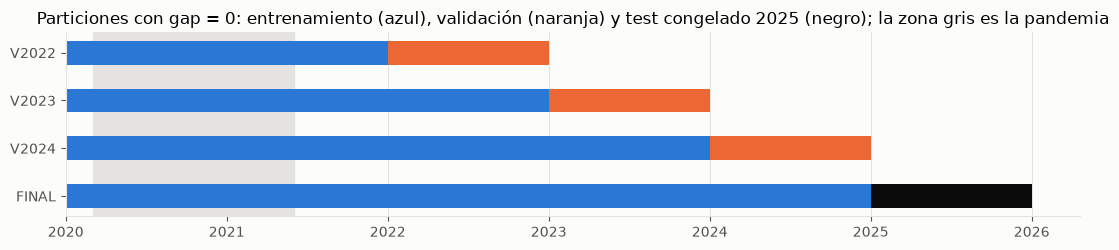

In [4]:
fig, ax = plt.subplots(figsize=(11, 2.6))
principal = ft.loc[ft["gap"].eq(0)]
rows = [
    (r.fold, *(pd.Period(mes, "M") for mes in (r.train_desde, r.train_hasta, r.val_desde, r.val_hasta)))
    for r in principal.itertuples()
]
for i, (n, a, b, c, d) in enumerate(rows[::-1]):
    ax.barh(i, (b - a).n + 1, left=a.ordinal, color=CAT[0], height=.5)
    ax.barh(i, (d - c).n + 1, left=c.ordinal, color=CAT[1] if n != "FINAL" else INK, height=.5)
ax.set_yticks(range(len(rows)), [r[0] for r in rows[::-1]])
ticks = pd.period_range("2019-01", "2026-01", freq="12M"); ax.set_xticks([t.ordinal for t in ticks], [str(t.year) for t in ticks])
pand = F.PANDEMIA; ax.axvspan(pand[0].ordinal, pand[-1].ordinal + 1, color=GRID, zorder=0)
ax.set_title("Particiones con gap = 0: entrenamiento (azul), validación (naranja) y test congelado 2025 (negro); la zona gris es la pandemia")
ax.grid(axis="y", visible=False); fig.tight_layout(); fig.savefig(FIG / "particiones.png", dpi=150); plt.show()

## 3. Controles de integridad temporal y de fuga

Estos controles repiten en el notebook las pruebas automatizadas de `tests/test_features.py`, que se ejecutan con `pytest`. Cada control se reporta como superado o fallido.

In [5]:
MODO_COLS = [f"hechos_modo_{m}" for m in F.MODOS]
def perturb_after(p, cut, seed=0):
    rng = np.random.default_rng(seed); p = p.copy(); m = p["mes"] > cut
    comp = rng.integers(0, 60, size=(m.sum(), len(MODO_COLS))); p.loc[m, MODO_COLS] = comp; p.loc[m, "y_hechos"] = comp.sum(axis=1); return p
checks = []
def check(nombre, cond, detalle=""):
    checks.append({"control": nombre, "resultado": "SUPERADO" if bool(cond) else "FALLIDO", "detalle": detalle})
# C1 unicidad y cobertura
check("C1 Panel único y completo (48 barrios × 84 meses)", X[["barrio", "mes_objetivo"]].drop_duplicates().shape[0] == len(X) == 4032)
check("C2 Variables completas desde 2020-01 en el desarrollo", dev[F.FEATURES_MAIN].notna().all().all() and dev["mes_objetivo"].min() == pd.Period("2020-01", "M"))
# C3 perturbación del futuro, en varios cortes y con ambas latencias
ok = True; n_cmp = 0
for gap in (0, 1):
    base_ = X if gap == 0 else X1
    for cut in ["2020-06", "2021-12", "2023-06", "2024-11"]:
        c = pd.Period(cut, "M"); Xp = F.build_features(perturb_after(panel, c), nb_, gap=gap)
        keep = base_["mes_ultimo_observado"] <= c
        ok &= base_.loc[keep, F.FEATURES_MAIN].reset_index(drop=True).equals(Xp.loc[keep, F.FEATURES_MAIN].reset_index(drop=True)); n_cmp += int(keep.sum())
check("C3 Cambiar datos posteriores al corte no altera las variables previas (gap 0 y 1; 4 cortes)", ok, f"{n_cmp} filas comparadas")
# C4 orden y zonas
Xs = F.build_features(panel.sample(frac=1, random_state=7), nb_)
check("C4 Variables independientes del orden de las filas", Xs[F.FEATURES_MAIN].equals(X[F.FEATURES_MAIN]))
y = panel.set_index(["barrio", "mes"])["y_hechos"]; sub = dev.sample(500, random_state=1)
check("C5 Los rezagos no cruzan barrios (y_lag1 manual = calculado)", np.allclose(sub["y_lag1"], [y.loc[(b, t - 1)] for b, t in zip(sub["barrio"], sub["mes_objetivo"])]))
# C6 objetivos
check("C6 y_target = hechos del panel en T; exactamente 10 positivos por mes", (X["y_target"].to_numpy() == y.loc[list(zip(X["barrio"], X["mes_objetivo"]))].to_numpy()).all()
      and (X.groupby("mes_objetivo")["top10_target"].sum() == 10).all())
# C7 particiones
test_m = set(pd.period_range("2025-01", "2025-12", freq="M"))
c7 = all(X.loc[fo["train"], "mes_objetivo"].max() < X.loc[fo["val"], "mes_objetivo"].min() and not (fo["train"] & fo["val"]).any()
         and not set(X.loc[fo["train"] | fo["val"], "mes_objetivo"]) & test_m for fo in folds) and not set(X.loc[tr_fin, "mes_objetivo"]) & test_m
check("C7 Entrenamiento estrictamente anterior a la validación; test nunca usado en desarrollo", c7)
check("C8 Variables del entrenamiento observadas antes del inicio de la validación", all((X.loc[fo["train"], "mes_ultimo_observado"] < X.loc[fo["val"], "mes_objetivo"].min()).all() for fo in folds))
# C9 preprocesador ajustado solo con entrenamiento
pre = F.make_preprocessor().fit(X.loc[folds[0]["train"]]); sc = pre.named_transformers_["num"].named_steps["escalar"]
num = [c for c in F.FEATURES_MAIN if c not in F.FEATURES_CAT]
check("C9 Escalado e imputación ajustados solo con el entrenamiento del fold", np.allclose(sc.mean_, X.loc[folds[0]["train"], num].mean().to_numpy()))
# C10 exclusiones
prohib = ["ksi", "grave", "mortal", "anomalia_mes", "registro", "km_vias", "avenida", "semaforo", "conteo_vehicular"]
check("C10 Sin variables excluidas (infraestructura, exposición, gravedad, anomalía del objetivo)", not any(p in c for c in F.FEATURES_MAIN for p in prohib))
# C11 gap
check("C11 Con gap = 1, el último mes observable es T−2", (X1["mes_ultimo_observado"] == X1["mes_objetivo"] - 2).all())
# C12 mismas particiones para ambas tareas
check("C12 Regresión y clasificación comparten filas y fechas de partición", all(X.loc[fo["val"], ["y_target", "top10_target"]].notna().all().all() for fo in folds))
ultimo_objetivo_train = pd.PeriodIndex(ft["train_hasta"], freq="M")
ultimo_observable = pd.PeriodIndex(ft["ultimo_observable"], freq="M")
check("C13 Etiquetas disponibles al inicio de la evaluación", (ultimo_objetivo_train <= ultimo_observable).all(),
      f"{len(ft)} particiones auditadas con gap 0 y 1")
ctab = pd.DataFrame(checks); ctab.to_csv(TAB / "controles_fuga.csv", index=False)
M["controles"] = ctab.to_dict(orient="records"); assert (ctab["resultado"] == "SUPERADO").all(); ctab

,control,resultado,detalle
0,C1 Panel único y completo (48 barrios × 84 meses),SUPERADO,
1,C2 Variables completas desde 2020-01 en el des...,SUPERADO,
2,C3 Cambiar datos posteriores al corte no alter...,SUPERADO,17760 filas comparadas
3,C4 Variables independientes del orden de las f...,SUPERADO,
4,C5 Los rezagos no cruzan barrios (y_lag1 manua...,SUPERADO,
5,C6 y_target = hechos del panel en T; exactamen...,SUPERADO,
6,C7 Entrenamiento estrictamente anterior a la v...,SUPERADO,
7,C8 Variables del entrenamiento observadas ante...,SUPERADO,
8,C9 Escalado e imputación ajustados solo con el...,SUPERADO,
9,"C10 Sin variables excluidas (infraestructura, ...",SUPERADO,


## 4. Exploración descriptiva de las variables (solo desarrollo)

Se calculan distribuciones y correlaciones con los meses objetivo 2020–2024. **No se seleccionan variables a partir de esta exploración.** El conjunto principal está fijado a priori, y cualquier selección o regularización se ajustará dentro de cada *fold* en los Pasos 07 y 08. La exploración sirve para anticipar colinealidad y escalas.

In [6]:
num = [c for c in F.FEATURES_MAIN if c not in F.FEATURES_CAT]
desc = dev[num].describe().T[["mean", "std", "min", "50%", "max"]].round(3); desc.to_csv(TAB / "descriptivos_variables_desarrollo.csv")
corr_y = dev[num].corrwith(dev["y_target"], method="spearman").sort_values(ascending=False).round(3)
cm = dev[num].corr(method="spearman")
pairs = cm.where(np.triu(np.ones(cm.shape, bool), 1)).stack().sort_values(ascending=False)
M["exploracion"] = {"spearman_con_y_target_top8": corr_y.head(8).to_dict(), "pares_spearman_mayor_0_95": int((pairs.abs() > .95).sum()),
                    "top_pares_colineales": {f"{a}~{b}": round(v, 3) for (a, b), v in pairs.head(6).items()}}
corr_y.to_csv(TAB / "spearman_variables_vs_objetivo_desarrollo.csv")
print(json.dumps(M["exploracion"], indent=1, ensure_ascii=False)); desc

{
 "spearman_con_y_target_top8": {
  "y_ma6": 0.839,
  "y_ma3": 0.833,
  "y_ma12": 0.828,
  "share_ma12": 0.81,
  "y_lag1": 0.786,
  "y_lag2": 0.763,
  "y_lag3": 0.758,
  "share_lag1": 0.737
 },
 "pares_spearman_mayor_0_95": 6,
 "top_pares_colineales": {
  "y_ma6~y_ma12": 0.973,
  "y_ma3~y_ma6": 0.97,
  "y_ma12~share_ma12": 0.957,
  "y_ma3~y_ma12": 0.934,
  "y_ma6~share_ma12": 0.932,
  "y_lag2~y_ma3": 0.926
 }
}


,mean,std,min,50%,max
y_lag1,14.422,11.695,0.000,11.000,86.000
y_lag2,14.285,11.581,0.000,11.000,81.000
y_lag3,14.249,11.529,0.000,11.000,81.000
y_lag12,14.434,11.691,0.000,11.000,99.000
y_ma3,14.319,10.930,0.333,11.333,76.667
y_ma6,14.287,10.635,1.000,11.333,75.333
y_ma12,14.329,10.418,1.417,11.583,67.083
tendencia_ma3_ma12,1.004,0.257,0.072,1.017,2.167
share_lag1,0.021,0.016,0.000,0.017,0.122
share_ma12,0.021,0.014,0.003,0.019,0.087


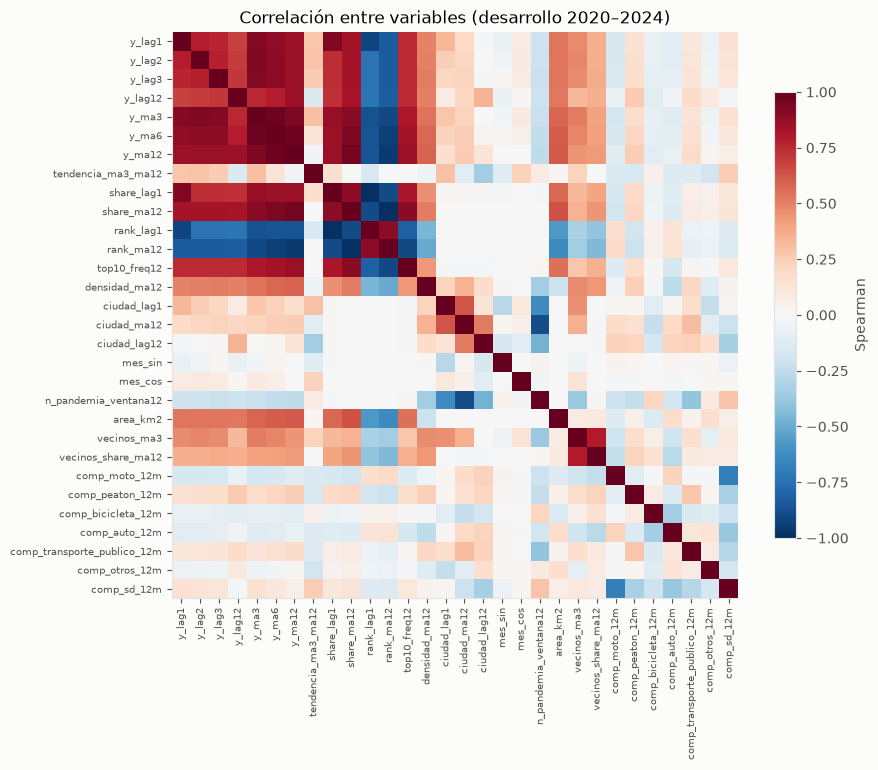

In [7]:
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm.values, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(num)), num, rotation=90, fontsize=7); ax.set_yticks(range(len(num)), num, fontsize=7)
fig.colorbar(im, ax=ax, shrink=.7, label="Spearman"); ax.set_title("Correlación entre variables (desarrollo 2020–2024)")
fig.tight_layout(); fig.savefig(FIG / "correlacion_variables.png", dpi=150); plt.show()

**Lectura.**
- Las variables históricas del barrio (rezagos, medias, participación y puesto) están muy correlacionadas entre sí. Por eso, los modelos lineales del Paso 07 y la regresión logística del Paso 08 necesitan **regularización** o un conjunto reducido, ajustado dentro de cada *fold*. Los árboles toleran la colinealidad, pero su importancia de variables se reparte entre variables redundantes. Esto debe tenerse en cuenta al interpretar SHAP en el Paso 08.
- La fuerte asociación del historial con el objetivo anticipa que la **persistencia será un baseline difícil de superar** (E6).

## 5. Baselines y métricas fijadas antes de modelar

Los baselines, las métricas y los umbrales de mejora relevante están en el [protocolo experimental](../docs/experimental_protocol.md), secciones 4 y 5. Aquí solo se verifica que las columnas de los baselines existan y estén completas. **No se evalúa ningún desempeño en este paso.**

In [8]:
BASELINES = {"persistencia": "y_lag1", "estacional": "y_lag12", "media12": "y_ma12"}
print({k: bool(dev[v].notna().all()) for k, v in BASELINES.items()})

{'persistencia': True, 'estacional': True, 'media12': True}


## 6. Artefactos

In [9]:
for gap, XX in ((0, X), (1, X1)):
    p = ROOT / "data" / "processed" / f"features_barrio_mes_h1_g{gap}.csv"
    XX.astype({"mes_objetivo": str, "mes_ultimo_observado": str}).to_csv(p, index=False)
    M[f"sha256_features_g{gap}"] = hashlib.sha256(p.read_bytes()).hexdigest()
(TAB / "fe_metrics.json").write_text(json.dumps(M, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print({k: v[:16] for k, v in M.items() if k.startswith("sha256")})

{'sha256_features_g0': '77df3f304c9f4bc5', 'sha256_features_g1': 'b5011a85ad6eb980'}
